### Imports & Loading Data

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Plot styling
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

# Load clean processed dataset
df = pd.read_csv("../data/processed/github_repos_clean.csv")
print(f"Dataset shape: {df.shape}")
df.head(3)

Dataset shape: (19166, 19)


,stargazers_count,forks_count,open_issues_count,watchers_count,size_kb,has_wiki,has_pages,has_projects,has_discussions,has_license,topics_count,description_length,repo_age_days,days_since_last_push,is_high_quality,lang_JavaScript,lang_Python,lang_TypeScript,owner_type_org
0,0,0,0,0,1817,1,0,1,0,0,0,0,92,92,0,0,1,0,0
1,0,0,0,0,3000,1,0,1,0,0,0,85,485,92,0,0,1,0,0
2,0,0,0,0,2204,1,0,1,0,1,0,42,92,92,0,0,1,0,0


### Feature Matrix(X) & Target(y) Separation

In [2]:
# Separate features and target
X = df.drop(columns=["is_high_quality"])
y = df["is_high_quality"]

print(f"Features (X) shape: {X.shape}")
print(f"Target (y) shape: {y.shape}")
print(f"Target balance:\n{y.value_counts(normalize=True).round(4) * 100}")

Features (X) shape: (19166, 18)
Target (y) shape: (19166,)
Target balance:
is_high_quality
1    50.02
0    49.98
Name: proportion, dtype: float64


### Train/Test Split & Scaling

In [3]:
# 80/20 stratified split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Train set: {X_train.shape[0]} rows")
print(f"Test set:  {X_test.shape[0]} rows")

# Scale features strictly on X_train to prevent data leakage
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert scaled arrays back to DataFrames for convenience
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X.columns)

Train set: 15332 rows
Test set:  3834 rows


### Train Baseline Models

In [4]:
# 1. Logistic Regression (uses scaled features)
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_scaled, y_train)

# 2. Random Forest (uses raw features, parallelized across all CPU cores)
rf = RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

print("Both models trained successfully!")

Both models trained successfully!


### Evaluation Comparison Function

In [5]:
def evaluate_model(name, model, X_tr, y_tr, X_te, y_te):
    # Predictions
    y_train_pred = model.predict(X_tr)
    y_test_pred = model.predict(X_te)
    
    # Probabilities for ROC-AUC
    y_test_prob = model.predict_proba(X_te)[:, 1]
    
    metrics = {
        "Model": name,
        "Train Acc": accuracy_score(y_tr, y_train_pred),
        "Test Acc": accuracy_score(y_te, y_test_pred),
        "Precision": precision_score(y_te, y_test_pred),
        "Recall": recall_score(y_te, y_test_pred),
        "F1-Score": f1_score(y_te, y_test_pred),
        "ROC-AUC": roc_auc_score(y_te, y_test_prob)
    }
    return metrics

# Compare both models side-by-side
results = [
    evaluate_model("Logistic Regression", log_reg, X_train_scaled, y_train, X_test_scaled, y_test),
    evaluate_model("Random Forest", rf, X_train, y_train, X_test, y_test)
]

comparison_df = pd.DataFrame(results).round(4)
comparison_df

,Model,Train Acc,Test Acc,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.8941,0.8931,0.8919,0.8947,0.8933,0.9632
1,Random Forest,0.9976,0.9802,0.9858,0.9745,0.9801,0.9981


### Confusion Matrices

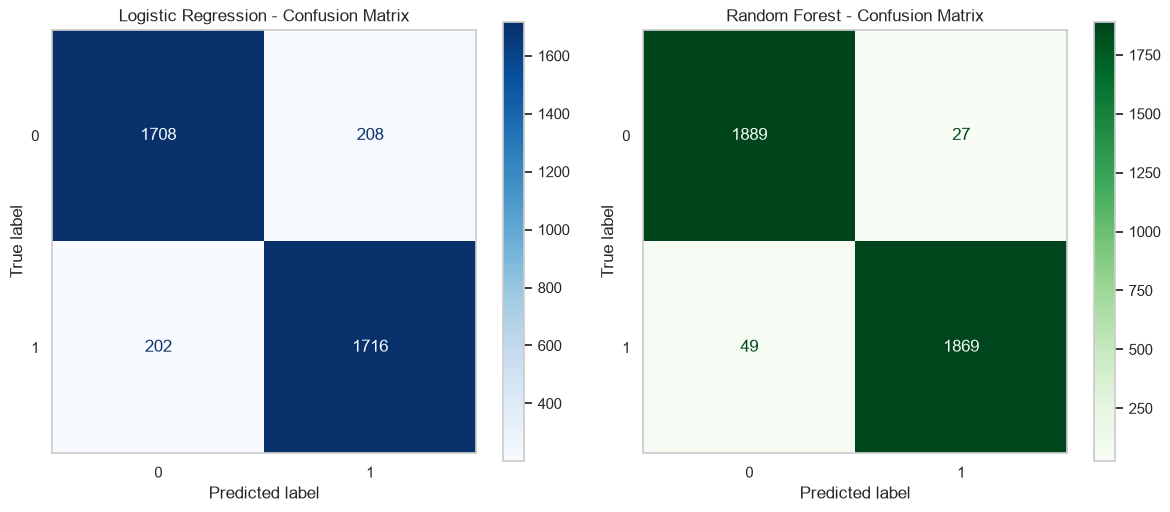

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Logistic Regression
disp_lr = ConfusionMatrixDisplay.from_estimator(log_reg, X_test_scaled, y_test, cmap="Blues", ax=axes[0])
axes[0].set_title("Logistic Regression - Confusion Matrix")
axes[0].grid(False)

# Random Forest
disp_rf = ConfusionMatrixDisplay.from_estimator(rf, X_test, y_test, cmap="Greens", ax=axes[1])
axes[1].set_title("Random Forest - Confusion Matrix")
axes[1].grid(False)

plt.tight_layout()
plt.show()

### Feature Importance

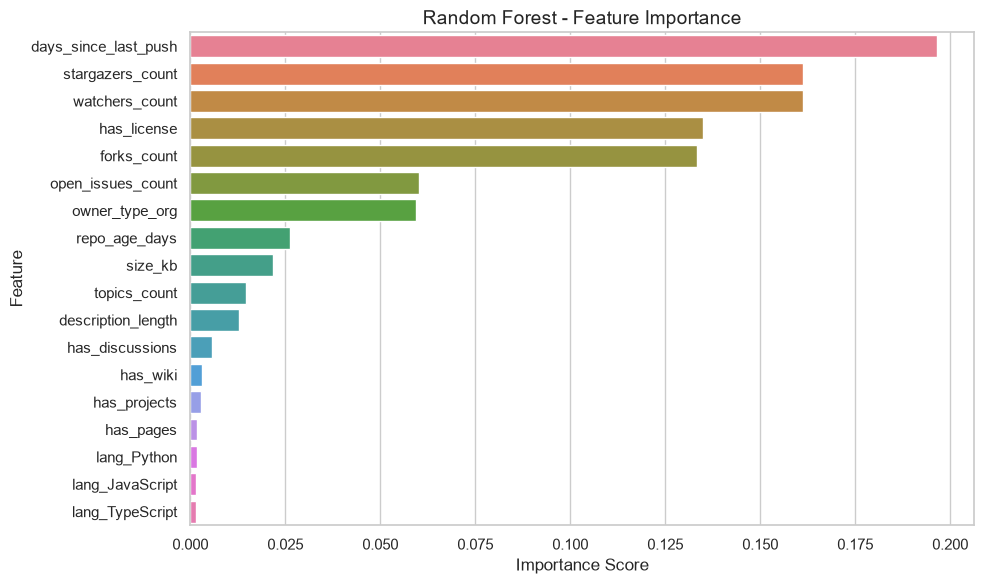

,Feature,Logistic_Reg_Coef,Random_Forest_Importance
13,days_since_last_push,-1.537258,0.196428
0,stargazers_count,13.229934,0.161213
3,watchers_count,13.229934,0.161114
9,has_license,1.455485,0.135001
1,forks_count,11.606511,0.133423
2,open_issues_count,4.447414,0.060058
17,owner_type_org,0.879645,0.059417
12,repo_age_days,0.149428,0.026199
4,size_kb,0.096204,0.021615
10,topics_count,0.310666,0.014651


In [7]:
# Create a DataFrame of feature importances
importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Logistic_Reg_Coef": log_reg.coef_[0],
    "Random_Forest_Importance": rf.feature_importances_
}).sort_values(by="Random_Forest_Importance", ascending=False)

# Plot Random Forest Top Features
plt.figure(figsize=(10, 6))
sns.barplot(
    data=importance_df, 
    x="Random_Forest_Importance", 
    y="Feature", 
    hue="Feature", 
    legend=False
)
plt.title("Random Forest - Feature Importance", fontsize=14)
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

importance_df

### Saving the models

In [ ]:
# Save Random Forest
joblib.dump(rf, "../models/random_forest_v1.pkl")

# Save Logistic Regression & its Scaler
joblib.dump(log_reg, "../models/logistic_regression_v1.pkl")
joblib.dump(scaler, "../models/scaler_v1.pkl")

print("All models and scalers saved successfully!")

All models and scalers saved successfully!


### Performing check on real life examples

In [ ]:
import requests
from dotenv import load_dotenv

# Load GitHub Token from .env
load_dotenv("../.env")
GITHUB_TOKEN = os.getenv("GITHUB_TOKEN")
HEADERS = {
    "Authorization": f"token {GITHUB_TOKEN}",
    "Accept": "application/vnd.github.v3+json"
}

def predict_repo(repo_full_name, model=rf):
    """
    Fetches a live repo from GitHub API, extracts our 18 features,
    and returns the model's quality prediction.
    """
    url = f"https://api.github.com/repos/{repo_full_name}"
    resp = requests.get(url, headers=HEADERS)
    
    if resp.status_code != 200:
        print(f"❌ Error fetching {repo_full_name}: HTTP {resp.status_code}")
        return
        
    data = resp.json()
    now = pd.Timestamp.now(tz="UTC")
    
    # 1. Extract raw features
    created_at = pd.to_datetime(data.get("created_at"), utc=True)
    pushed_at = pd.to_datetime(data.get("pushed_at"), utc=True)
    
    features = {
        "stargazers_count": data.get("stargazers_count", 0),
        "forks_count": data.get("forks_count", 0),
        "open_issues_count": data.get("open_issues_count", 0),
        "watchers_count": data.get("watchers_count", 0),
        "size_kb": data.get("size", 0),
        "has_wiki": int(data.get("has_wiki", False)),
        "has_pages": int(data.get("has_pages", False)),
        "has_projects": int(data.get("has_projects", False)),
        "has_discussions": int(data.get("has_discussions", False)),
        "has_license": int(bool(data.get("license"))),
        "topics_count": len(data.get("topics", [])),
        "description_length": len(data.get("description", "") or ""),
        "repo_age_days": (now - created_at).days,
        "days_since_last_push": (now - pushed_at).days,
        "lang_JavaScript": int(data.get("language") == "JavaScript"),
        "lang_Python": int(data.get("language") == "Python"),
        "lang_TypeScript": int(data.get("language") == "TypeScript"),
        "owner_type_org": int(data.get("owner", {}).get("type") == "Organization")
    }
    
    # Ensure columns match our training feature matrix X exactly
    repo_df = pd.DataFrame([features])[X.columns]
    
    # Predict with Random Forest
    prob_high = model.predict_proba(repo_df)[0][1]
    prediction = "🌟 HIGH QUALITY" if prob_high >= 0.5 else "⚠️ LOW / AVERAGE QUALITY"
    
    print("=" * 60)
    print(f"📦 Repository: {repo_full_name} ({data.get('language')})")
    print(f"   Stars: {features['stargazers_count']:,} | Forks: {features['forks_count']:,} | Pushed: {features['days_since_last_push']} days ago")
    print(f"   License: {bool(features['has_license'])} | Owner: {data.get('owner', {}).get('type')}")
    print(f"   Prediction: {prediction} (Confidence: {prob_high*100:.1f}%)")
    print("=" * 60)

In [14]:
# Test 1: Elite open source project
predict_repo("facebook/react")

# Test 2: Standard high-quality Python library
predict_repo("pallets/flask")

# Test 3: The famous beginner demo repo (untouched for years)
predict_repo("octocat/Hello-World")

📦 Repository: facebook/react (JavaScript)
   Stars: 252,094 | Forks: 51,620 | Pushed: 2 days ago
   License: True | Owner: Organization
   Prediction: 🌟 HIGH QUALITY (Confidence: 100.0%)
📦 Repository: pallets/flask (Python)
   Stars: 75,164 | Forks: 17,281 | Pushed: 3 days ago
   License: True | Owner: Organization
   Prediction: 🌟 HIGH QUALITY (Confidence: 100.0%)
📦 Repository: octocat/Hello-World (None)
   Stars: 3,896 | Forks: 7,348 | Pushed: 803 days ago
   License: False | Owner: User
   Prediction: 🌟 HIGH QUALITY (Confidence: 89.0%)
